# Chapitre 6 - Cours 3 : Un RAG de bout en bout, et au-delà du texte

Les cours 1 et 2 ont construit et optimisé le retriever. Branchons-le maintenant sur un
générateur (Qwen2.5-0.5B-Instruct) et mesurons ce que le RAG change réellement aux réponses.
On termine par la section *RAG Beyond Texts* : RAG sur des données tabulaires (text-to-SQL) et
RAG multimodal.

Plan :

1. assembler un RAG complet (recherche hybride, reranking, prompt, génération) ;
2. avec ou sans contexte : mesurer l'apport du RAG, l'abstention et les hallucinations ;
3. évaluer composant par composant : erreurs du retriever ou du générateur ?
4. combien de passages donner, et où placer le bon ?
5. RAG sur données tabulaires : text-to-SQL sur une base de ventes ;
6. RAG multimodal.

In [1]:
import os

os.environ["HF_HUB_OFFLINE"] = "1"          # modèles déjà en cache : aucun appel réseau
os.environ["HF_HUB_VERBOSITY"] = "error"
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import llm
from aie import ch06_rag_agents as c6
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

set_style()
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 120)
P = c6.passages()
TEXTS, IDS = [p.text for p in P], [p.pid for p in P]
TXT = dict(zip(IDS, TEXTS))
Q = c6.QUESTIONS
tok, _ = llm.load(llm.SMALL)
ntok_msgs = lambda m: len(tok.apply_chat_template(m, tokenize=True, return_dict=True)["input_ids"])  # noqa: E731

## 1. Assembler un RAG complet (section *RAG Architecture*)

Notre pipeline reprend les meilleurs choix du cours 2 :

1. **recherche hybride** : BM25 et embeddings multilingues, top-20 chacun, fusion RRF ;
2. **reranking** des 20 candidats par le cross-encoder `bge-reranker-v2-m3` ;
3. **prompt** : consigne système (répondre à partir des documents, sinon dire « Je ne sais
   pas »), puis les $k$ passages numérotés, puis la question ;
4. **génération** gloutonne par Qwen2.5-0.5B-Instruct (température 0, donc déterministe).

Le livre note que l'article original entraînait retriever et générateur ensemble ; nous
assemblons, comme la plupart des équipes, des composants pré-entraînés séparément.

In [2]:
bm25 = c6.TermRetriever(TEXTS, IDS)
dense = c6.DenseRetriever(TEXTS, IDS)

def retrieve(question, k=3, rerank=True):
    cand = [d_ for d_, _ in c6.rrf([bm25.search(question, 20), dense.search(question, 20)])][:20]
    if rerank:
        s = c6.cross_encoder_scores(question, [TXT[d_] for d_ in cand])
        cand = [cand[i] for i in np.argsort(-s, kind="stable")]
    return cand[:k]

def rag_messages(question, contexts):
    if contexts is None:  # pas de RAG : le modèle répond de mémoire
        return [{"role": "system", "content": "Tu réponds en français, en une ou deux phrases."},
                {"role": "user", "content": question}]
    return [{"role": "system", "content": c6.RAG_SYSTEM}, {"role": "user", "content": c6.build_rag_prompt(question, contexts)}]

q0 = Q[4]["question"]
ctx0 = retrieve(q0)
msgs0 = rag_messages(q0, [TXT[d_] for d_ in ctx0])
print("Passages retenus :", ctx0)
print("-" * 100)
print(msgs0[1]["content"][:900], "...")
print("-" * 100)
print("Réponse :", c6.generate_batch([msgs0], max_new_tokens=48)[0])

Passages retenus : ['thermo-8', 'thermo-1', 'rh-4']
----------------------------------------------------------------------------------------------------
Documents :
[Document 1]
Le Thermo-X200 est garanti trois ans à compter de la date d'achat, sur présentation de la facture. La garantie ne couvre pas les dommages causés par une installation non conforme ou par une surtension. Une extension de garantie de deux années supplémentaires peut être souscrite en ligne.

[Document 2]
Le Thermo-X200 est un thermostat connecté conçu par la société Domotik pour les maisons équipées d'une chaudière ou d'une pompe à chaleur. Il mesure la température toutes les trente secondes et ajuste le chauffage pièce par pièce. Son écran tactile de 3,5 pouces affiche la consigne et la consommation du jour.

[Document 3]
La période d'essai dure deux mois pour les employés et quatre mois pour les cadres. Elle peut être renouvelée une fois, avec l'accord écrit du salarié. Pendant cette période, chaque partie peut 

Réponse : Trois ans.


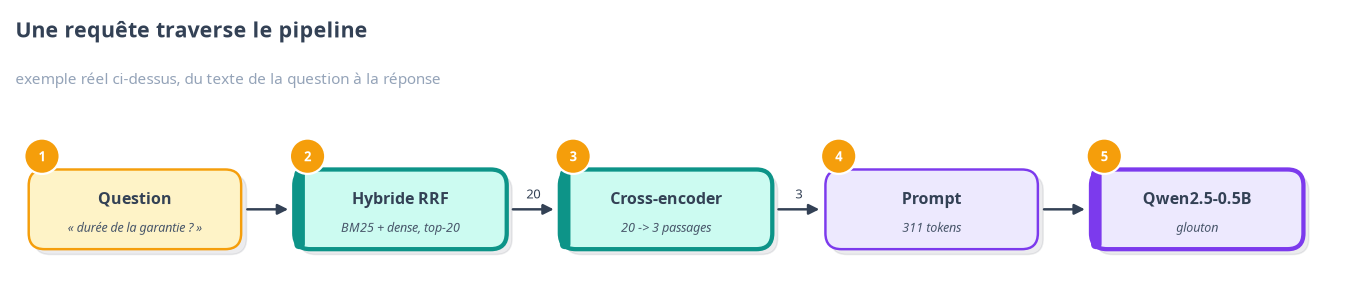

In [3]:
d = Diagram(15, 2.2, title="Une requête traverse le pipeline", subtitle="exemple réel ci-dessus, du texte de la question à la réponse")
d.box("q", 1.4, 0.9, "Question", sub="« durée de la garantie ? »", color=AMBER, w=2.4)
d.box("hyb", 4.4, 0.9, "Hybride RRF", sub="BM25 + dense, top-20", color=TEAL, w=2.4, kind="model")
d.box("ce", 7.4, 0.9, "Cross-encoder", sub="20 -> 3 passages", color=TEAL, w=2.4, kind="model")
d.box("pr", 10.4, 0.9, "Prompt", sub=f"{ntok_msgs(msgs0)} tokens", color=VIOLET, w=2.4)
d.box("gen", 13.4, 0.9, "Qwen2.5-0.5B", sub="glouton", color=VIOLET, kind="model", w=2.4)
for a, b, lab in [("q", "hyb", None), ("hyb", "ce", "20"), ("ce", "pr", "3"), ("pr", "gen", None)]:
    d.arrow(a, b, lab)
for i, x in enumerate([1.4, 4.4, 7.4, 10.4, 13.4], start=1):
    d.badge(x - 1.05, 1.5, str(i))
d.show()

> **À retenir.** Un RAG complet tient en une dizaine de lignes : recherche, reranking,
> gabarit de prompt, génération. Toute la difficulté est dans la qualité de chaque étage et
> dans la façon de les évaluer.

## 2. Avec ou sans contexte (section *RAG*)

Lewis et al. (2020) ont montré qu'un accès à l'information pertinente rend les réponses plus
précises et réduit les hallucinations. Vérifions-le sur nos 42 questions, dans quatre
conditions :

- **sans contexte** : le modèle répond de mémoire ;
- **RAG** : les 3 passages du pipeline ;
- **oracle** : uniquement le passage pertinent annoté (borne haute pour le générateur) ;
- **hors sujet** : 3 passages tirés au hasard parmi les non pertinents (le bon comportement est
  alors de répondre « Je ne sais pas »).

Une réponse est jugée correcte si elle contient l'une des variantes attendues (par exemple «
25 » pour les congés). C'est un juge grossier mais transparent ; les chapitres 3 et 4 discutent
de juges plus fins.

168 générations en 16 s


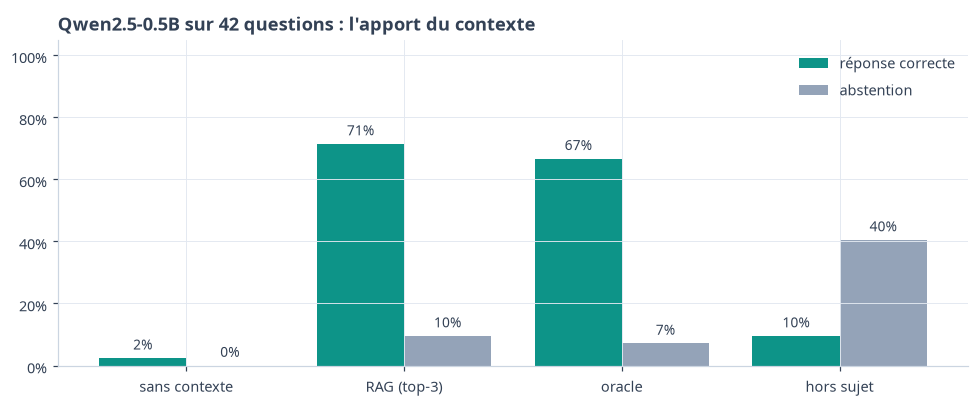

,exactitude,abstention (« Je ne sais pas »)
sans contexte,0.024,0.000
RAG (top-3),0.714,0.095
oracle,0.667,0.071
hors sujet,0.095,0.405


In [4]:
rng = np.random.default_rng(0)
top3 = {q["qid"]: retrieve(q["question"], 3) for q in Q}
conditions = {
    "sans contexte": [rag_messages(q["question"], None) for q in Q],
    "RAG (top-3)": [rag_messages(q["question"], [TXT[d_] for d_ in top3[q["qid"]]]) for q in Q],
    "oracle": [rag_messages(q["question"], [TXT[max(q["relevant"], key=q["relevant"].get)]]) for q in Q],
    "hors sujet": [rag_messages(q["question"], [TXT[d_] for d_ in rng.choice([i for i in IDS if i not in q["relevant"]], 3, replace=False)])
                   for q in Q],
}
t = time.perf_counter()
reponses = {c: c6.generate_batch(m, max_new_tokens=48) for c, m in conditions.items()}
print(f"{4 * len(Q)} générations en {time.perf_counter() - t:.0f} s")
res = pd.DataFrame({c: {"exactitude": np.mean([c6.answer_ok(a, q["answers"]) for a, q in zip(r, Q)]),
                        "abstention (« Je ne sais pas »)": np.mean([c6.abstains(a) for a in r])}
                    for c, r in reponses.items()}).T

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(res))
ax.bar(x - 0.2, res["exactitude"], 0.4, color=TEAL, label="réponse correcte")
ax.bar(x + 0.2, res["abstention (« Je ne sais pas »)"], 0.4, color=GRAY, label="abstention")
annotate_bars(ax, "{:.0%}")
ax.set_xticks(x); ax.set_xticklabels(res.index); ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Qwen2.5-0.5B sur 42 questions : l'apport du contexte"); ax.legend()
plt.tight_layout(); plt.show()
res.round(3)

In [5]:
choix = [4, 7, 12, 28, 31, 32]
pd.DataFrame([{"question": Q[i]["question"], "sans contexte": reponses["sans contexte"][i][:110],
               "RAG": reponses["RAG (top-3)"][i][:110]} for i in choix])

,question,sans contexte,RAG
0,Quelle est la durée de la garantie du Thermo-X200 ?,La garantie Thermo-X200 est de 1 an.,Trois ans.
1,Combien de jours de vacances ai-je par an chez Calypso ?,Calypso propose des vacances d'été pour 10 jours par an.,Je ne sais pas.
2,Quel montant puis-je dépenser pour me former chaque année ?,"Pour déterminer le montant de votre formation annuelle, il vous faudra :\n\n1. Évaluer vos besoins spécifiques (",Je ne sais pas.
3,Combien de temps la lumière solaire met-elle à nous parvenir ?,La lumière solaire se déplace à travers l'air et atteint notre planète environ 90 minutes.,Huit minutes et vingt secondes.
4,Combien coûte le Fedora Fruité ?,Le coût exact de l'installation et de la mise à jour du système d'exploitation Fedora Fruite varie selon les m,18 euros
5,À partir de quel montant la livraison est-elle gratuite chez Minou Chic ?,La livraison est gratuite chez Minou Chic pour tout achat de plus de 100€.,De 50 euros jusqu'à 100 points.


Sans contexte, le modèle ne peut pas connaître les faits fictifs (prix de Minou Chic, règles
RH de Calypso, codes du Thermo-X200) : il **invente** avec aplomb une garantie, un prix, un
plafond. Avec le contexte, l'exactitude bondit. Surprise : l'« oracle » (le seul passage
annoté) ne fait pas mieux que le RAG à 3 passages. Les deux conditions diffèrent de quelques
questions seulement, et les passages voisins du même document aident parfois le petit modèle
à comprendre de quoi parle le passage clé. L'écart entre ces deux conditions et 100 % est la part
du **générateur** : un modèle de 0,5 milliard de paramètres lit mal certains passages ou
répond « Je ne sais pas » alors que la réponse est là (par exemple, il ne relie pas
« vacances » à « congés payés »). Avec des passages hors sujet, il s'abstient souvent (c'est le comportement
demandé), mais pas toujours : il lui arrive d'inventer malgré la consigne.

> **À retenir.** Le RAG transforme un modèle qui hallucine en un modèle qui **lit** : sur des
> faits absents des données d'entraînement, c'est la seule façon d'obtenir des réponses
> justes. La condition « hors sujet » mesure la capacité à **s'abstenir**, aussi importante
> que l'exactitude.

## 3. Évaluer composant par composant (section *Retrieval Algorithms*)

Le livre recommande d'évaluer un RAG **par composant** (qualité de la recherche, des
embeddings) **et de bout en bout** (qualité des réponses). Croisons les deux pour chaque
question : le bon passage figurait-il dans le top-3 ? la réponse est-elle correcte ? Les quatre
cases ne demandent pas la même correction.

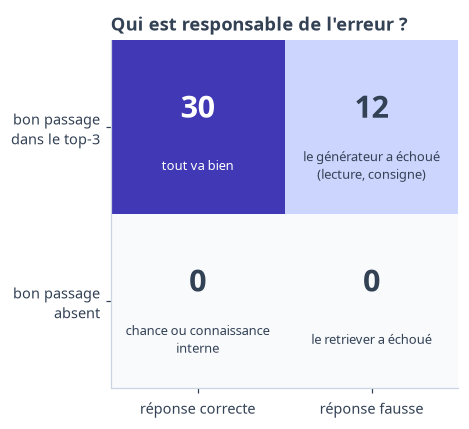

,question,attendu,réponse RAG
0,Que signifie le code E-42 sur le Thermo-X200 ?,sonde,Le code E-42 signifie que le Thermo-X200 a été mis en œuvre avec une fonctionnalité de surveillance thermique intégrée.
1,"Mon thermostat affiche que les piles sont faibles, que faire ?",AAA,Remplissez les piles avec des batteries.
2,Combien de jours de vacances ai-je par an chez Calypso ?,25,Je ne sais pas.
3,Combien de jours par semaine puis-je travailler depuis chez moi ?,trois,Je ne sais pas.
4,Quel montant puis-je dépenser pour me former chaque année ?,1 500,Je ne sais pas.


In [6]:
hit = np.array([any(d_ in q["relevant"] for d_ in top3[q["qid"]]) for q in Q])
ok = np.array([c6.answer_ok(a, q["answers"]) for a, q in zip(reponses["RAG (top-3)"], Q)])
M = np.array([[np.sum(hit & ok), np.sum(hit & ~ok)], [np.sum(~hit & ok), np.sum(~hit & ~ok)]])
fig, ax = plt.subplots(figsize=(6.8, 4))
ax.imshow(M, cmap="aie_seq", vmin=0, vmax=M.max() * 1.3)
labels = [["tout va bien", "le générateur a échoué\n(lecture, consigne)"],
          ["chance ou connaissance\ninterne", "le retriever a échoué"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i - 0.12, str(M[i, j]), ha="center", va="center", fontsize=20, fontweight="bold",
                color="white" if M[i, j] > M.max() * 0.65 else SLATE)
        ax.text(j, i + 0.22, labels[i][j], ha="center", va="center", fontsize=8.5,
                color="white" if M[i, j] > M.max() * 0.65 else SLATE)
ax.set_xticks([0, 1]); ax.set_xticklabels(["réponse correcte", "réponse fausse"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["bon passage\ndans le top-3", "bon passage\nabsent"])
ax.grid(False); ax.set_title("Qui est responsable de l'erreur ?")
plt.tight_layout(); plt.show()
fails = [q for q, h, o in zip(Q, hit, ok) if h and not o][:5]
pd.DataFrame([{"question": q["question"], "attendu": q["answers"][0],
               "réponse RAG": reponses["RAG (top-3)"][Q.index(q)][:120]} for q in fails])

Grâce au cross-encoder, le retriever ne rate presque rien : l'essentiel des erreurs vient du
**générateur**, qui avait le bon passage sous les yeux. Lire ces cas est instructif : réponses
partielles, confusion entre deux passages voisins, abstention injustifiée, ou réponse correcte
formulée autrement que nos variantes attendues (une limite de notre juge par sous-chaîne).
Améliorer encore le retriever ne servirait donc à rien ici : il faudrait un meilleur
générateur, un meilleur prompt, ou un juge plus fin.

> **À retenir.** Croiser « le bon passage a-t-il été récupéré ? » et « la réponse est-elle
> correcte ? » indique **quel composant** améliorer. Un RAG s'évalue par composant **et** de
> bout en bout.